# Check of CRDS files

In [2]:
!crds sync --all

CRDS - INFO -  0 errors
CRDS - INFO -  0 warnings
CRDS - INFO -  0 infos


# L1 -> L2 [multi-threading]

In [ ]:
import time
import dask
from dask.distributed import Client
from romancal.pipeline import ExposurePipeline as ELP
import os
import warnings
import logging
from glob import glob as gb
    
# Ignore warnings
warnings.filterwarnings('ignore')
# Ignore INFO
logging.getLogger().setLevel(logging.CRITICAL)

# Reduce uncal files
ufiles = gb('./Uncal/*_000[2-6]_wfi*uncal.asdf')
steps = {'source_catalog':{'skip': True}}

# Create output directory
outdir = '.Cal/'
# Check if directory exists, otherwise creates it
os.makedirs(outdir, exist_ok=True)



client = Client()
    
# Optional: Prints the local dashboard URL (usually http://localhost:8787)
print(f"Dask Dashboard is live at: {client.dashboard_link}")

# 2. Set up parallel execution tasks lazily using dask.delayed    
print("Building execution graph...")
lazy_tasks = [dask.delayed(ELP.call)(ufile, steps=steps, save_results=True, update_version=True, output_dir=outdir) for ufile in ufiles]

# 3. Trigger parallel computation across workers
print("Executing parallel tasks...")
start_time = time.time()
    
# .compute() forces the evaluation of the delayed task graph
results = dask.compute(*lazy_tasks)
    
end_time = time.time()

# 4. Handle results and close down resources neatly
print(f"Execution finished in {end_time - start_time:.2f} seconds.")
print(f"Results: {results}")
    
# Properly shutdown the cluster workers
client.close()

In [1]:
from glob import glob as gb
import os

# Remove the wcs files
wcsfiles = gb('./Cal/*_wcs.asdf')
for wcsfile in wcsfiles:
    os.remove(wcsfile)

# Background files [multi-threading]

In [2]:
import time
import dask
from dask.distributed import Client
from glob import glob as gb
import os
from flo.wfiskymatch import asdf2healpix
import logging
import warnings


# Ignore warnings
warnings.filterwarnings('ignore')
# Ignore INFO
logging.getLogger().setLevel(logging.CRITICAL)

path = './'
outdir = path + 'Bkg/'
# Check if directory exists, otherwise creates it
os.makedirs(outdir, exist_ok=True)
files = sorted(gb(os.path.join(path,'./Cal/*_cal.asdf')))

client = Client()
print(f"Dask Dashboard is live at: {client.dashboard_link}")
lazy_tasks = [dask.delayed(asdf2healpix)(file, outdir, savefits=False) for file in files]

# 3. Trigger parallel computation across workers
print("Executing parallel tasks...")
start_time = time.time()
    
# .compute() forces the evaluation of the delayed task graph
results = dask.compute(*lazy_tasks)
end_time = time.time()

# 4. Handle results and close down resources neatly
print(f"Execution finished in {end_time - start_time:.2f} seconds.")
print(f"Results: {results}")
    
# Properly shutdown the cluster workers
client.close()

Dask Dashboard is live at: http://127.0.0.1:8787/status
Executing parallel tasks...


/Users/dfadda/Roman/Repositories/Github/flo/flo/wfiskymatch.py:570: RuntimeWarning: overflow encountered in multiply
  err *= dn2mjy
/Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/astropy/nddata/blocks.py:160: RuntimeWarning: All-NaN slice encountered
  return func(reshaped, axis=axis)
/Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/astropy/nddata/blocks.py:160: RuntimeWarning: All-NaN slice encountered
  return func(reshaped, axis=axis)
/Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/astropy/nddata/blocks.py:160: RuntimeWarning: All-NaN slice encountered
  return func(reshaped, axis=axis)
/Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/astropy/nddata/blocks.py:160: RuntimeWarning: All-NaN slice encountered
  return func(reshaped, axis=axis)
/Users/dfadda/miniconda3/envs/flo/lib/python3.14/site-packages/astropy/nddata/blocks.py:160: RuntimeWarning: All-NaN slice encountered
  return func(reshaped, axis=axis)
/Users/dfadda/min

Execution finished in 148.44 seconds.
Results: (None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None)
file  r0105901001001007002_0005_wfi11_f213_cal  read in  1.7638468742370605
file  r0105901001001007002_0004_wfi08_f213_cal  read in  1.9700100421905518
file  r0105901001001007002_0005_wfi05_f213_cal  read in  2.1079189777374268
Median bkg rms  0.10291667
Median bkg rms  0.076899454
Median bkg rms  0.088

In [3]:
# Computing offsets
from flo.wfiskymatch import pixmatch
from glob import glob as gb
import os

path = './'
outdir = path + 'Bkg/'
files = sorted(gb(os.path.join(outdir,'*cal.h5')))

object = 'field'
offsets = pixmatch(files, outfile=outdir+object+'_offsets', offsets=None)

for file, offset in zip(files, offsets):
    print(file, offset)

./Bkg/r0105901001001007002_0001_wfi01_f213_cal.h5 -0.3592264783796056
./Bkg/r0105901001001007002_0001_wfi02_f213_cal.h5 0.04042353132142431
./Bkg/r0105901001001007002_0001_wfi03_f213_cal.h5 -0.07358185392828104
./Bkg/r0105901001001007002_0001_wfi04_f213_cal.h5 0.021152360162926074
./Bkg/r0105901001001007002_0001_wfi05_f213_cal.h5 -0.03158953395167754
./Bkg/r0105901001001007002_0001_wfi06_f213_cal.h5 0.17020495567250138
./Bkg/r0105901001001007002_0001_wfi07_f213_cal.h5 -0.14497366797808575
./Bkg/r0105901001001007002_0001_wfi08_f213_cal.h5 0.017418201289902287
./Bkg/r0105901001001007002_0001_wfi09_f213_cal.h5 -0.018787825854436502
./Bkg/r0105901001001007002_0001_wfi10_f213_cal.h5 -0.15805301362559365
./Bkg/r0105901001001007002_0001_wfi11_f213_cal.h5 -0.01652744010146654
./Bkg/r0105901001001007002_0001_wfi12_f213_cal.h5 0.1669082805556203
./Bkg/r0105901001001007002_0001_wfi13_f213_cal.h5 -0.0644142302284864
./Bkg/r0105901001001007002_0001_wfi14_f213_cal.h5 0.041798805367233974
./Bkg/r0105

In [1]:
# Add offsets to original images - create new files
from flo.wfiskymatch import addOffset
import h5py
import os

path = './'
bkgpath = path + 'Bkg/'
h5file = bkgpath + 'field_offsets.h5'
with h5py.File(h5file, 'r') as hdf5_file:
    files = hdf5_file['files'][:]
    offsets = hdf5_file['offsets'][:]

# Create new files with added offsets
outdir = path + '/Offset/'
l2path = path + '/Cal/'
os.makedirs(outdir, exist_ok=True)
for file, offset in zip(files,offsets):
    print(file.decode(), offset)
    L2 = l2path + file.decode() +'.asdf'
    addOffset(L2, offset=offset, outdir = outdir)

r0105901001001007002_0001_wfi01_f213_cal -0.35922647
r0105901001001007002_0001_wfi02_f213_cal 0.04042353
r0105901001001007002_0001_wfi03_f213_cal -0.07358185
r0105901001001007002_0001_wfi04_f213_cal 0.02115236
r0105901001001007002_0001_wfi05_f213_cal -0.031589534
r0105901001001007002_0001_wfi06_f213_cal 0.17020495
r0105901001001007002_0001_wfi07_f213_cal -0.14497367
r0105901001001007002_0001_wfi08_f213_cal 0.017418202
r0105901001001007002_0001_wfi09_f213_cal -0.018787825
r0105901001001007002_0001_wfi10_f213_cal -0.15805301
r0105901001001007002_0001_wfi11_f213_cal -0.01652744
r0105901001001007002_0001_wfi12_f213_cal 0.16690828
r0105901001001007002_0001_wfi13_f213_cal -0.06441423
r0105901001001007002_0001_wfi14_f213_cal 0.041798804
r0105901001001007002_0001_wfi15_f213_cal -0.106588826
r0105901001001007002_0001_wfi16_f213_cal 0.0062303734
r0105901001001007002_0001_wfi17_f213_cal 0.25514314
r0105901001001007002_0001_wfi18_f213_cal 0.28001252
r0105901001001007002_0002_wfi01_f213_cal -0.3501

# Find GAIA sources in the field

In [2]:
# Get the list of coordinates at the time of the observation
from flo.simutils import gaiastars
import roman_datamodels as rdm

with rdm.open('Cal/r0105901001001007002_0006_wfi12_f213_cal.asdf') as dm:
    astro = dm.meta.wcs
    ra0, dec0 = astro(2044.5,2044.5)
    start_time = dm.meta.exposure.start_time

radius = 1.0  # Radius of the catalog in degrees

# Retrieve catalog and save it locally
gaia_catalog = gaiastars(ra=ra0, dec=dec0, radius=radius, star=0.5, maglim=16, obs_time=start_time)
gaia_catalog.write('gaia_catalog.ecsv', format='ascii.ecsv', overwrite=True)


**WARNING**: LOCAL JWST PRD VERSION PRDOPSSOC-073 DOESN'T MATCH THE CURRENT ONLINE VERSION PRDOPSSOC-075
Please consider updating pysiaf, e.g. pip install --upgrade pysiaf or conda update pysiaf


The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


2026-10-27 11:44:38 INFO     Query finished.


INFO: Query finished. [astroquery.utils.tap.core]


# Desaturate stars

In [1]:
# Desaturate the PSFs
from flo.desaturate import desaturatePsf
from astropy.coordinates import SkyCoord
from astropy.table import Table
from glob import glob as gb

path = './Offset/'
ufiles = gb(path + 'r*_off_cal.asdf')

gaia_catalog = Table.read('gaia_catalog.ecsv')
stars = SkyCoord(gaia_catalog['ra'].value, gaia_catalog['dec'].value, unit='deg', frame = 'icrs')

for L2 in ufiles:
    desaturatePsf(L2, stars)

No GAIA stars in this image
PSF substitution for 48 non GAIA saturated sources 
Corrected a total of 48 saturated sources
No GAIA stars in this image
PSF substitution for 47 non GAIA saturated sources 
Corrected a total of 47 saturated sources
No GAIA stars in this image
PSF substitution for 50 non GAIA saturated sources 
Corrected a total of 50 saturated sources
No GAIA stars in this image
PSF substitution for 119 non GAIA saturated sources 
Corrected a total of 119 saturated sources
No GAIA stars in this image
PSF substitution for 43 non GAIA saturated sources 
Corrected a total of 43 saturated sources
No GAIA stars in this image
PSF substitution for 100 non GAIA saturated sources 
Corrected a total of 100 saturated sources
No GAIA stars in this image
PSF substitution for 43 non GAIA saturated sources 
Corrected a total of 43 saturated sources
No GAIA stars in this image
PSF substitution for 117 non GAIA saturated sources 
Corrected a total of 117 saturated sources


/Users/dfadda/Roman/Repositories/Github/flo/flo/desaturate.py:53: RuntimeWarning: All-NaN slice encountered
  srcext = np.nanmedian(subimage[idx_ext])


No GAIA stars in this image
PSF substitution for 27 non GAIA saturated sources 
Corrected a total of 27 saturated sources
No GAIA stars in this image
PSF substitution for 76 non GAIA saturated sources 
Corrected a total of 76 saturated sources
No GAIA stars in this image
PSF substitution for 44 non GAIA saturated sources 
Corrected a total of 44 saturated sources
No GAIA stars in this image
PSF substitution for 25 non GAIA saturated sources 
Corrected a total of 25 saturated sources


/Users/dfadda/Roman/Repositories/Github/flo/flo/desaturate.py:53: RuntimeWarning: All-NaN slice encountered
  srcext = np.nanmedian(subimage[idx_ext])
/Users/dfadda/Roman/Repositories/Github/flo/flo/desaturate.py:54: RuntimeWarning: All-NaN slice encountered
  srcbkg = np.nanmedian(subimage[idx_bkg])


No GAIA stars in this image
PSF substitution for 29 non GAIA saturated sources 
Corrected a total of 29 saturated sources
No GAIA stars in this image
PSF substitution for 44 non GAIA saturated sources 
Corrected a total of 44 saturated sources
There are 6 bright stars which will be corrected
PSF substitution for 46 non GAIA saturated sources 
Corrected a total of 52 saturated sources
No GAIA stars in this image
PSF substitution for 32 non GAIA saturated sources 
Corrected a total of 32 saturated sources
No GAIA stars in this image
PSF substitution for 69 non GAIA saturated sources 
Corrected a total of 69 saturated sources


...

/Users/dfadda/Roman/Repositories/Github/flo/flo/desaturate.py:53: RuntimeWarning: All-NaN slice encountered
  srcext = np.nanmedian(subimage[idx_ext])


No GAIA stars in this image
PSF substitution for 40 non GAIA saturated sources 
Corrected a total of 40 saturated sources
No GAIA stars in this image
PSF substitution for 51 non GAIA saturated sources 
Corrected a total of 51 saturated sources
No GAIA stars in this image
PSF substitution for 60 non GAIA saturated sources 
Corrected a total of 60 saturated sources
No GAIA stars in this image
PSF substitution for 118 non GAIA saturated sources 
Corrected a total of 118 saturated sources
No GAIA stars in this image
PSF substitution for 40 non GAIA saturated sources 
Corrected a total of 40 saturated sources
No GAIA stars in this image
PSF substitution for 108 non GAIA saturated sources 
Corrected a total of 108 saturated sources
No GAIA stars in this image
PSF substitution for 34 non GAIA saturated sources 
Corrected a total of 34 saturated sources
No GAIA stars in this image
PSF substitution for 117 non GAIA saturated sources 
Corrected a total of 117 saturated sources


/Users/dfadda/Roman/Repositories/Github/flo/flo/desaturate.py:53: RuntimeWarning: All-NaN slice encountered
  srcext = np.nanmedian(subimage[idx_ext])


No GAIA stars in this image
PSF substitution for 30 non GAIA saturated sources 
Corrected a total of 30 saturated sources
No GAIA stars in this image
PSF substitution for 79 non GAIA saturated sources 
Corrected a total of 79 saturated sources
No GAIA stars in this image
PSF substitution for 44 non GAIA saturated sources 
Corrected a total of 44 saturated sources
No GAIA stars in this image
PSF substitution for 30 non GAIA saturated sources 
Corrected a total of 30 saturated sources
No GAIA stars in this image
PSF substitution for 35 non GAIA saturated sources 
Corrected a total of 35 saturated sources
No GAIA stars in this image
PSF substitution for 32 non GAIA saturated sources 
Corrected a total of 32 saturated sources
There are 3 bright stars which will be corrected
PSF substitution for 31 non GAIA saturated sources 
Corrected a total of 34 saturated sources
No GAIA stars in this image
PSF substitution for 27 non GAIA saturated sources 
Corrected a total of 27 saturated sources
No 

/Users/dfadda/Roman/Repositories/Github/flo/flo/desaturate.py:53: RuntimeWarning: All-NaN slice encountered
  srcext = np.nanmedian(subimage[idx_ext])


In [1]:
# Mask bad pixels

from glob import glob as gb
from flo.badpixels import maskNegativePixels
import os 

path = './Offset/'
ufiles = gb(path + 'r*_off_cal.asdf')

for ufile in ufiles:
    maskNegativePixels(ufile)

./Offset/r0105901001001007002_0001_wfi01_f213_off_cal.asdf: 0.14% negative non-masked pixels, median 2.3
./Offset/r0105901001001007002_0001_wfi02_f213_off_cal.asdf: 0.02% negative non-masked pixels, median 2.6
./Offset/r0105901001001007002_0001_wfi03_f213_off_cal.asdf: 0.04% negative non-masked pixels, median 2.5
./Offset/r0105901001001007002_0001_wfi04_f213_off_cal.asdf: 0.07% negative non-masked pixels, median 2.0
./Offset/r0105901001001007002_0001_wfi05_f213_off_cal.asdf: 0.13% negative non-masked pixels, median 2.3
./Offset/r0105901001001007002_0001_wfi06_f213_off_cal.asdf: 0.03% negative non-masked pixels, median 2.3
./Offset/r0105901001001007002_0001_wfi07_f213_off_cal.asdf: 0.12% negative non-masked pixels, median 1.5
./Offset/r0105901001001007002_0001_wfi08_f213_off_cal.asdf: 0.02% negative non-masked pixels, median 1.8
./Offset/r0105901001001007002_0001_wfi09_f213_off_cal.asdf: 0.02% negative non-masked pixels, median 1.8
./Offset/r0105901001001007002_0001_wfi10_f213_off_cal.a

# Create association file for mosaic

In [1]:
# Association files

from flo.mosaic import make_cells_asn
from glob import glob as gb
import os

path = './Offset/'
files = gb(path + 'r*_off_cal.asdf')
refdir = os.environ.get('CRDS_PATH')+'references/roman/wfi/'
make_cells_asn(files, outname='test', refdir=refdir)

Median orientation is -169.5402827440039 degrees
orientation  -169.5402827440039
0 1 ['./Offset/r0105901001001007002_0002_wfi18_f213_off_cal.asdf', './Offset/r0105901001001007002_0003_wfi18_f213_off_cal.asdf', './Offset/r0105901001001007002_0004_wfi18_f213_off_cal.asdf', './Offset/r0105901001001007002_0005_wfi18_f213_off_cal.asdf']
0 2 ['./Offset/r0105901001001007002_0002_wfi17_f213_off_cal.asdf', './Offset/r0105901001001007002_0002_wfi18_f213_off_cal.asdf', './Offset/r0105901001001007002_0003_wfi17_f213_off_cal.asdf', './Offset/r0105901001001007002_0003_wfi18_f213_off_cal.asdf', './Offset/r0105901001001007002_0004_wfi17_f213_off_cal.asdf', './Offset/r0105901001001007002_0004_wfi18_f213_off_cal.asdf', './Offset/r0105901001001007002_0005_wfi17_f213_off_cal.asdf', './Offset/r0105901001001007002_0005_wfi18_f213_off_cal.asdf']
0 3 ['./Offset/r0105901001001007002_0002_wfi16_f213_off_cal.asdf', './Offset/r0105901001001007002_0002_wfi17_f213_off_cal.asdf', './Offset/r0105901001001007002_0003_

# Run mosaic on tiles [multi-threading]

In [2]:
# Tiles 
from glob import glob as gb
from romancal.pipeline import MosaicPipeline as MP
import time
import dask
from dask.distributed import Client
import os
import logging
import warnings

path = './'
asnfiles = gb(path+'test*.asn')

steps = {'outlier_detection':{'skip':True},
         'skymatch':{'skip':True},
         'resample':{'resample_on_skycell':True},
         'source_catalog':{'skip':True},
        }

client = Client()
    
# Optional: Prints the local dashboard URL (usually http://localhost:8787)
print(f"Dask Dashboard is live at: {client.dashboard_link}")

# 2. Set up parallel execution tasks lazily using dask.delayed    
print("Building execution graph...")
lazy_tasks = [dask.delayed(MP.call)(asnfile,save_results=True, resample_on_skycell=True,steps=steps) for asnfile in asnfiles]

# 3. Trigger parallel computation across workers
print("Executing parallel tasks...")
start_time = time.time()
    
# .compute() forces the evaluation of the delayed task graph
results = dask.compute(*lazy_tasks)
    
end_time = time.time()

# 4. Handle results and close down resources neatly
print(f"Execution finished in {end_time - start_time:.2f} seconds.")
print(f"Results: {results}")
    
# Properly shutdown the cluster workers
client.close()

Dask Dashboard is live at: http://127.0.0.1:8787/status
Building execution graph...
Executing parallel tasks...


2026-10-27 12:12:18,481 - romancal.associations._association - WARNING - Cannot validate: <class 'romancal.associations._association._Association'> has no schema. Presuming OK.
2026-10-27 12:12:18,481 - romancal.associations._association - WARNING - Cannot validate: <class 'romancal.associations._association._Association'> has no schema. Presuming OK.
2026-10-27 12:12:18,481 - romancal.associations._association - WARNING - Cannot validate: <class 'romancal.associations._association._Association'> has no schema. Presuming OK.
2026-10-27 12:12:18,482 - romancal.associations._association - WARNING - Cannot validate: <class 'romancal.associations._association._Association'> has no schema. Presuming OK.
2026-10-27 12:12:18,482 - romancal.associations._association - WARNING - Cannot validate: <class 'romancal.associations._association._Association'> has no schema. Presuming OK.
2026-10-27 12:12:18,482 - romancal.associations._association - WARNING - Cannot validate: <class 'romancal.associat

RecursionError: maximum recursion depth exceeded

# Stitch tiles into final mosaic

In [3]:
from glob import glob as gb
from flo.mosaic import stitchCells

path = './'
asdffiles = gb(path+'test*.asdf')

stitchCells(asdffiles, outname='Carina_F213_tiles')

Rotation angle is:  -349.540283203127
Scale is:  3.0212006096855075e-05


# Display final mosaic

Pixel scale from wcs  [0.10876322 0.10876322]  arcsec
size of image:  (18184, 28527)


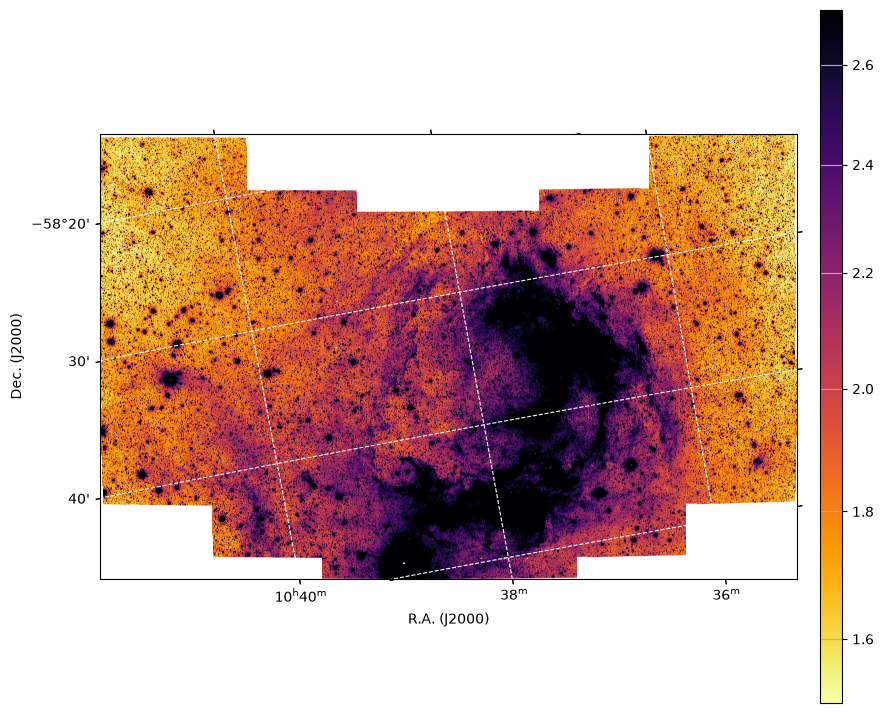

In [4]:
# Display mosaic
import matplotlib.pyplot as plt
import roman_datamodels as rdm
from astropy import visualization
from astropy.table import Table
import numpy as np
from astropy.wcs.utils import proj_plane_pixel_scales as ppps
from astropy.wcs import WCS
from astropy.io import fits

with fits.open('Carina_F213_tiles.fits') as f:
    image = f[0].data
    header = f[0].header

wcs = WCS(header)
print('Pixel scale from wcs ', ppps(wcs)*3600, ' arcsec')
print('size of image: ', np.shape(image))
norm = visualization.ImageNormalize(image,
                                    interval=visualization.ZScaleInterval(contrast=1),
                                    stretch=visualization.AsinhStretch(a=1))

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={'projection':wcs})

plot = ax.imshow(image, norm=norm,  origin='lower',cmap='inferno_r')
ax.coords.grid(True, color='white', ls='dashed')
ax.coords[0].set_axislabel('R.A. (J2000)')
ax.coords[1].set_axislabel('Dec. (J2000)')

cax = plt.axes([0.925, 0.11, 0.025,0.77 ])
plt.colorbar(mappable=plot, cax=cax)
plt.grid()
plt.show()